### CREDIT RISK ASSESSMENT USING MULTIPLE LINEAR REGRESSION

In [39]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as pltS
import seaborn as sns

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [51]:
#=============================
# LOAD CSV file
#=============================

df = pd.read_csv("credit_risk_regression_dataset.csv")

print("Dataset loaded successfully")
print("shape of dataset: ",df.shape)

display(df.head())

Dataset loaded successfully
shape of dataset:  (200, 10)


,Applicant_ID,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years,Credit_Score
0,1,61,576000,0.07,4,8,0.24,5,3,341
1,2,26,1536000,0.07,1,4,0.24,4,0,484
2,3,56,840000,0.50,8,14,0.23,4,8,300
3,4,31,1536000,0.26,2,4,0.91,2,1,413
4,5,26,1404000,0.11,5,5,0.77,5,7,322


In [52]:
#==========================
# Inspect The Dataset
#==========================

print("========= DATASET SHAPE =========")
print(df.shape)

print("\n========= DATA TYPES =========")
df.info()

print("\n========= DESCRIPTIVE STATISTICS =========")
display(df.describe())

print("\n========== DUPLICATE ROWS ==========")
print("Number of duplicate rows:", df.duplicated().sum())

print("\n========== MISSING VALUES ==========")
display(df.isnull().sum())


========= DATASET SHAPE =========
(200, 10)

========= DATA TYPES =========
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Applicant_ID              200 non-null    int64  
 1   Age                       200 non-null    int64  
 2   Annual_Income_INR         200 non-null    int64  
 3   Debt_to_Income_Ratio      200 non-null    float64
 4   Late_Payments_12M         200 non-null    int64  
 5   Credit_History_Years      200 non-null    int64  
 6   Credit_Utilization_Ratio  200 non-null    float64
 7   Existing_Loans            200 non-null    int64  
 8   Employment_Years          200 non-null    int64  
 9   Credit_Score              200 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 15.8 KB

========= DESCRIPTIVE STATISTICS =========


,Applicant_ID,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years,Credit_Score
count,200.000000,200.000000,2.000000e+02,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,43.860000,1.036260e+06,0.382550,3.785000,11.150000,0.493750,3.010000,9.840000,383.890000
std,57.879185,13.105693,4.396210e+05,0.176726,2.529976,8.155986,0.265416,1.984842,6.888516,69.209012
min,1.000000,21.000000,2.640000e+05,0.060000,0.000000,1.000000,0.030000,0.000000,0.000000,300.000000
25%,50.750000,31.750000,6.450000e+05,0.250000,1.750000,4.000000,0.267500,1.000000,4.000000,322.000000
50%,100.500000,45.000000,1.062000e+06,0.370000,4.000000,10.000000,0.450000,3.000000,9.000000,376.500000
75%,150.250000,55.000000,1.416000e+06,0.540000,6.000000,18.000000,0.730000,5.000000,15.000000,431.250000
max,200.000000,65.000000,1.788000e+06,0.680000,8.000000,30.000000,0.950000,6.000000,25.000000,635.000000



========== DUPLICATE ROWS ==========
Number of duplicate rows: 0

========== MISSING VALUES ==========


Applicant_ID                0
Age                         0
Annual_Income_INR           0
Debt_to_Income_Ratio        0
Late_Payments_12M           0
Credit_History_Years        0
Credit_Utilization_Ratio    0
Existing_Loans              0
Employment_Years            0
Credit_Score                0
dtype: int64

In [45]:
# ============================================================
# DATA CLEANING / PREPARATION
# ============================================================

# REMOVE DUPLICATE ROW IF PRESENT
if df.duplicated().sum() >  0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

# Check missing values
if df.isnull().sum().sum() > 0:
    print("Missing values found.")
    df = df.dropna()
    print("Rows containing missing values removed.")
else:
    print("No missing values Found.")

print("\nShape after cleaning:", df.shape)

No duplicate rows found.
No missing values Found.

Shape after cleaning: (200, 9)


In [47]:
# ============================================================
# 4. REMOVE Applicant_ID
# ============================================================

# Applicant_ID is only an identifier,
# so it should not be used as a predictor.

df = df.drop("Applicant_ID", axis=1)

print("Applicant_ID removed.")

print(df.head())

KeyError: "['Applicant_ID'] not found in axis"

In [48]:
# ============================================================
# 5. SEPARATE X AND y
# ============================================================

# Independent variables / predictors
X = df.drop("Credit_Score", axis=1)

#Dependent Variable
y = df["Credit_Score"]

print("========== INDEPENDENT VARIABLES ==========")
print(X.columns.tolist())

print("\n========== DEPENDENT VARIABLE ==========")
print("Credit_Score")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

========== INDEPENDENT VARIABLES ==========
['Age', 'Annual_Income_INR', 'Debt_to_Income_Ratio', 'Late_Payments_12M', 'Credit_History_Years', 'Credit_Utilization_Ratio', 'Existing_Loans', 'Employment_Years']

========== DEPENDENT VARIABLE ==========
Credit_Score

X shape: (200, 8)
y shape: (200,)


In [9]:
# ============================================================
# 6. TRAIN-TEST SPLIT
# 80% TRAINING
# 20% TESTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Training percentage:",
    len(X_train) / len(X) * 100,
    "%"
)

print(
    "Testing percentage:",
    len(X_test) / len(X) * 100,
    "%"
)

Training samples: 160
Testing samples: 40
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [10]:
# ============================================================
# 7. CREATE AND TRAIN MULTIPLE LINEAR REGRESSION MODEL
# ============================================================

model = LinearRegression()

model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully.")

print("\nIntercept (β0):")
print(model.intercept_)

Multiple Linear Regression model trained successfully.

Intercept (β0):
410.07497658346506


In [11]:
# ============================================================
# 8. PREDICT CREDIT SCORES FOR TEST DATA
# ============================================================

y_pred = model.predict(X_test)

print("First 10 predictions:")

prediction_table = pd.DataFrame({
    "Actual Credit Score": y_test.values,
    "Predicted Credit Score": y_pred
})

display(prediction_table.head(10))

First 10 predictions:


,Actual Credit Score,Predicted Credit Score
0,325,349.358258
1,302,335.154823
2,300,224.629621
3,458,460.096033
4,407,422.872312
5,324,368.181398
6,342,355.010604
7,371,404.850371
8,537,490.954510
9,308,359.930921


In [12]:
# ============================================================
# 9. EVALUATE MODEL
# MAE, MSE, RMSE, R²
# ============================================================

# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Root Mean Squared Error
rmse = np.sqrt(mse)

# R² Score
r2 = r2_score(y_test, y_pred)


print("========== MODEL PERFORMANCE ==========")

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)


========== MODEL PERFORMANCE ==========
MAE  : 22.129091316066216
MSE  : 719.4408881508631
RMSE : 26.82239527243723
R²   : 0.8257714701798505


In [13]:
# ============================================================
# METRIC TABLE
# ============================================================

metrics_table = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],

    "Obtained Value": [
        mae,
        mse,
        rmse,
        r2
    ],

    "Interpretation": [
        "Average error in credit-score points",
        "Average squared prediction error",
        "Typical error in credit-score points",
        "Fraction of target variance explained"
    ]
})

display(metrics_table)

,Metric,Obtained Value,Interpretation
0,MAE,22.129091,Average error in credit-score points
1,MSE,719.440888,Average squared prediction error
2,RMSE,26.822395,Typical error in credit-score points
3,R²,0.825771,Fraction of target variance explained


In [14]:
# ============================================================
# 10. INTERPRET MODEL COEFFICIENTS
# ============================================================

coefficients = pd.Series(
    model.coef_, #provides the coefficient/weights of trained LinearRegression model
    index=X.columns
)

print("========== MODEL COEFFICIENTS ==========")

display(
    coefficients.to_frame("Coefficient")
)

print("\nIntercept (β0):", model.intercept_)

========== MODEL COEFFICIENTS ==========


,Coefficient
Age,-0.054044
Annual_Income_INR,0.000086
Debt_to_Income_Ratio,-138.191201
Late_Payments_12M,-16.219479
Credit_History_Years,2.805101
Credit_Utilization_Ratio,-65.775940
Existing_Loans,-4.594719
Employment_Years,1.854367



Intercept (β0): 410.07497658346506


In [15]:
# ============================================================
# COEFFICIENT INTERPRETATION
# ============================================================

print("\n========== COEFFICIENT INTERPRETATION ==========")

for feature, coefficient in coefficients.items():

    if coefficient >= 0:
        direction = "increase"
    else:
        direction = "decrease"

    print(
        f"{feature}: A one-unit increase is associated with "
        f"an estimated {abs(coefficient):.4f} point "
        f"{direction} in Credit_Score, "
        f"holding other predictors constant."
    )


========== COEFFICIENT INTERPRETATION ==========
Age: A one-unit increase is associated with an estimated 0.0540 point decrease in Credit_Score, holding other predictors constant.
Annual_Income_INR: A one-unit increase is associated with an estimated 0.0001 point increase in Credit_Score, holding other predictors constant.
Debt_to_Income_Ratio: A one-unit increase is associated with an estimated 138.1912 point decrease in Credit_Score, holding other predictors constant.
Late_Payments_12M: A one-unit increase is associated with an estimated 16.2195 point decrease in Credit_Score, holding other predictors constant.
Credit_History_Years: A one-unit increase is associated with an estimated 2.8051 point increase in Credit_Score, holding other predictors constant.
Credit_Utilization_Ratio: A one-unit increase is associated with an estimated 65.7759 point decrease in Credit_Score, holding other predictors constant.
Existing_Loans: A one-unit increase is associated with an estimated 4.5947 po

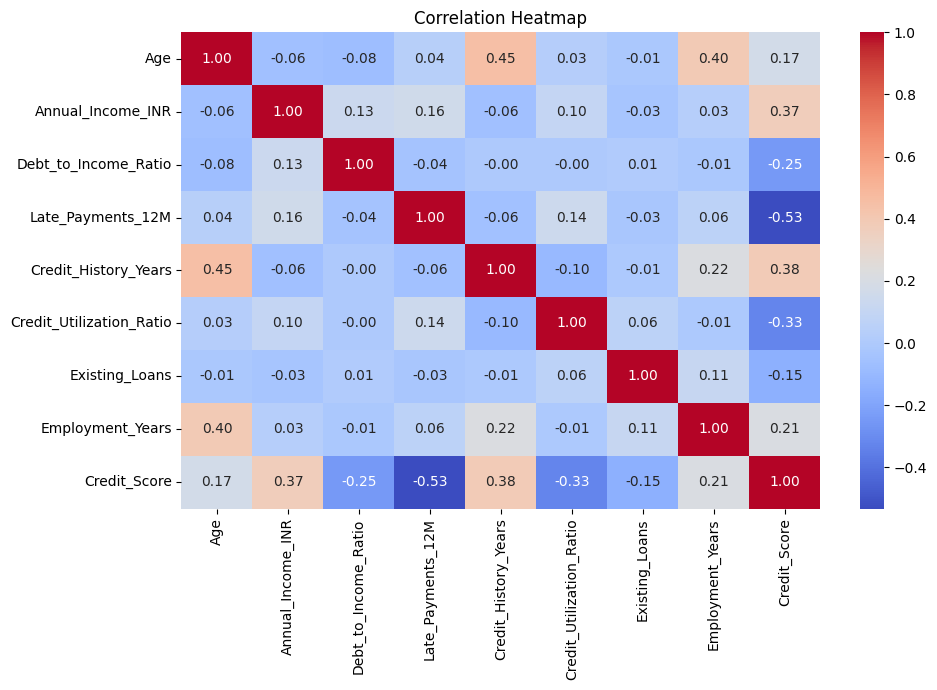

In [16]:
# ============================================================
# 11. CORRELATION HEATMAP
# ============================================================

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()

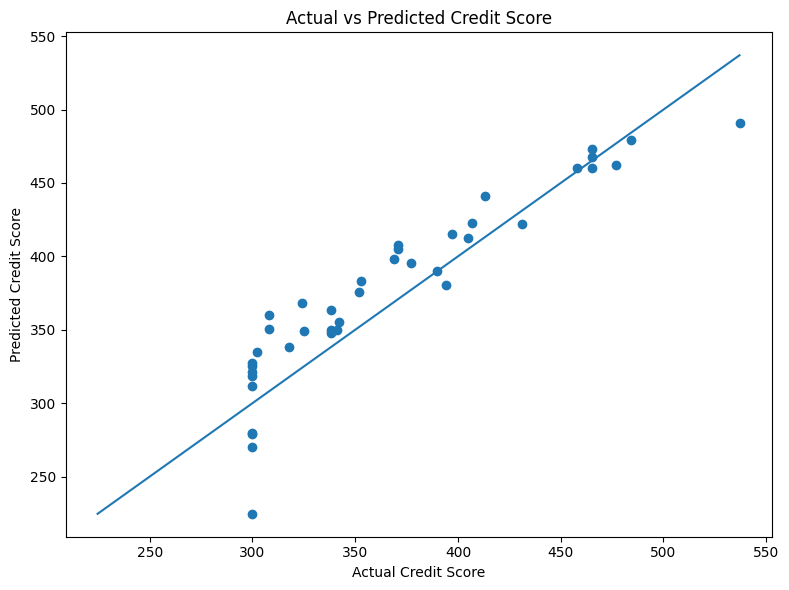

In [17]:
# ============================================================
# 12. ACTUAL VS PREDICTED PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

# Ideal prediction line
minimum = min(
    y_test.min(),
    y_pred.min()
)

maximum = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")

plt.title(
    "Actual vs Predicted Credit Score"
)

plt.tight_layout()

plt.show()


In [18]:
# ============================================================
# RESIDUAL CALCULATION
# ============================================================

residuals = y_test - y_pred

print("First 10 residuals:")

display(
    pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": y_pred,
        "Residual": residuals.values
    }).head(10)
)

First 10 residuals:


,Actual,Predicted,Residual
0,325,349.358258,-24.358258
1,302,335.154823,-33.154823
2,300,224.629621,75.370379
3,458,460.096033,-2.096033
4,407,422.872312,-15.872312
5,324,368.181398,-44.181398
6,342,355.010604,-13.010604
7,371,404.850371,-33.850371
8,537,490.954510,46.045490
9,308,359.930921,-51.930921


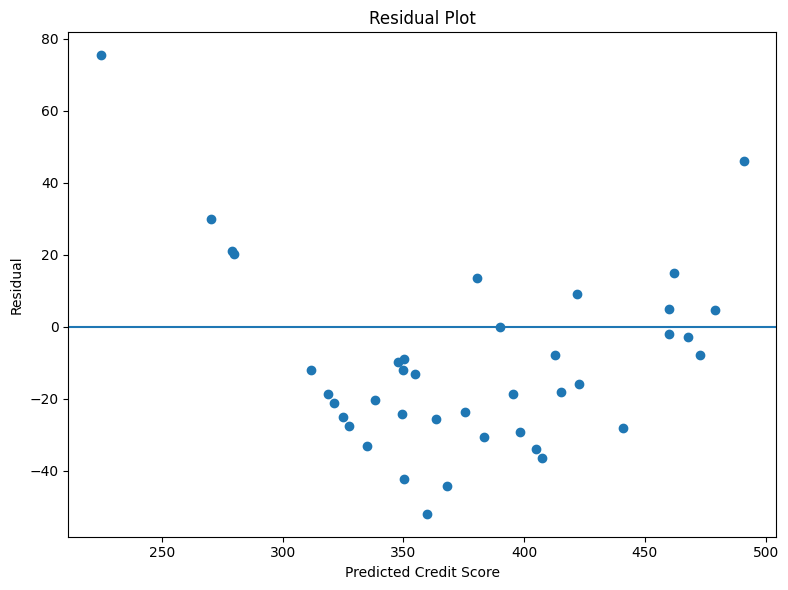

In [19]:
# ============================================================
# RESIDUAL PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(0)

plt.xlabel("Predicted Credit Score")
plt.ylabel("Residual")

plt.title("Residual Plot")

plt.tight_layout()

plt.show()

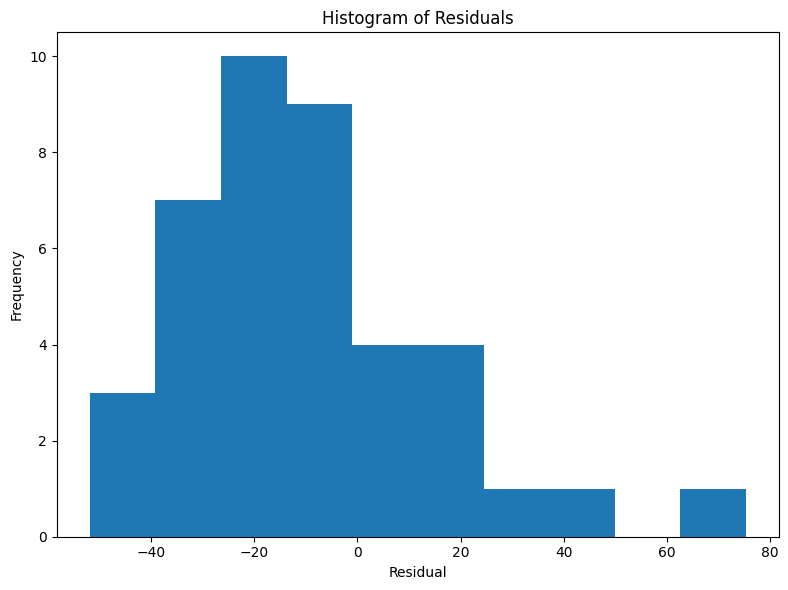

In [20]:
# ============================================================
# RESIDUAL HISTOGRAM
# APPROXIMATE NORMALITY CHECK
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist(
    residuals,
    bins=10
)

plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.title("Histogram of Residuals")

plt.tight_layout()

plt.show()


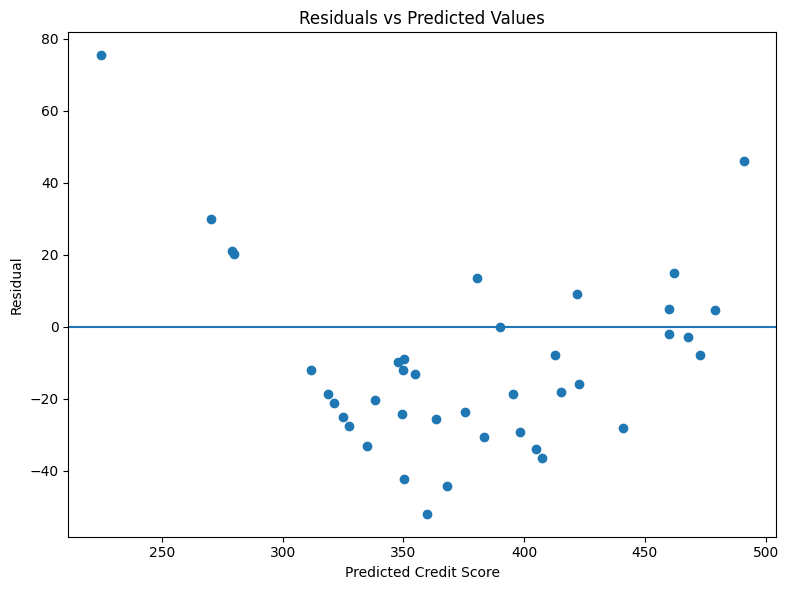

In [21]:
# ============================================================
# RESIDUALS VS PREDICTED
# LINEARITY + HOMOSCEDASTICITY INSPECTION
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(0)

plt.xlabel("Predicted Credit Score")
plt.ylabel("Residual")

plt.title(
    "Residuals vs Predicted Values"
)

plt.tight_layout()

plt.show()

In [22]:
# ============================================================
# ASSUMPTION CHECK — CORRELATION / MULTICOLLINEARITY
# ============================================================

print("""
Basic assumptions to inspect:

1. Linearity between predictors and target.
2. Independent observations.
3. Approximately constant residual variance
   (homoscedasticity).
4. Residuals approximately normal for
   statistical inference.
5. No severe multicollinearity among predictors.

Use:
- Actual vs Predicted plot
- Residual plot
- Residual histogram
- Correlation heatmap

for visual inspection.
""")



Basic assumptions to inspect:

1. Linearity between predictors and target.
2. Independent observations.
3. Approximately constant residual variance
   (homoscedasticity).
4. Residuals approximately normal for
   statistical inference.
5. No severe multicollinearity among predictors.

Use:
- Actual vs Predicted plot
- Residual plot
- Residual histogram
- Correlation heatmap

for visual inspection.



In [ ]:
# ============================================================
# NEW APPLICANT PREDICTION
# ============================================================

# Example applicant
# Replace these values if your teacher gives
# different applicant values.

new_applicant = pd.DataFrame({

    "Age": [30],

    "Annual_Income_INR": [600000],

    "Debt_to_Income_Ratio": [0.30],

    "Late_Payments_12M": [1],

    "Credit_History_Years": [6],

    "Credit_Utilization_Ratio": [0.25],

    "Existing_Loans": [2],

    "Employment_Years": [5]

})

predicted_score = model.predict(
    new_applicant
)

print(
    "Predicted Credit Score:",
    predicted_score[0]
)

Predicted Credit Score: 402.92482629798974


In [24]:
# ============================================================
# EXTENSION
# STANDARDIZED COEFFICIENTS
# ============================================================

scaled_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)


# Train scaled model
scaled_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None


In [25]:
# ============================================================
# STANDARDIZED COEFFICIENTS
# ============================================================

standardized_coefs = pd.Series(

    scaled_model
    .named_steps["linearregression"]
    .coef_,

    index=X.columns

).sort_values(
    key=abs,
    ascending=False
)


print(
    "========== STANDARDIZED COEFFICIENTS =========="
)

display(
    standardized_coefs.to_frame(
        "Standardized Coefficient"
    )
)


========== STANDARDIZED COEFFICIENTS ==========


,Standardized Coefficient
Late_Payments_12M,-40.410470
Annual_Income_INR,37.488791
Debt_to_Income_Ratio,-24.290407
Credit_History_Years,23.938458
Credit_Utilization_Ratio,-17.446882
Employment_Years,13.041168
Existing_Loans,-8.994244
Age,-0.714367


In [26]:
# ============================================================
# SCALED MODEL PREDICTION
# ============================================================

y_pred_scaled = scaled_model.predict(
    X_test
)


# ============================================================
# SCALED MODEL METRICS
# ============================================================

mae_scaled = mean_absolute_error(
    y_test,
    y_pred_scaled
)

mse_scaled = mean_squared_error(
    y_test,
    y_pred_scaled
)

rmse_scaled = np.sqrt(
    mse_scaled
)

r2_scaled = r2_score(
    y_test,
    y_pred_scaled
)

In [27]:
# ============================================================
# ORIGINAL VS SCALED MODEL
# ============================================================

scaled_metrics = pd.DataFrame({

    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],

    "Original Model": [
        mae,
        mse,
        rmse,
        r2
    ],

    "Scaled Model": [
        mae_scaled,
        mse_scaled,
        rmse_scaled,
        r2_scaled
    ]

})


display(
    scaled_metrics
)


,Metric,Original Model,Scaled Model
0,MAE,22.129091,22.129091
1,MSE,719.440888,719.440888
2,RMSE,26.822395,26.822395
3,R²,0.825771,0.825771


In [28]:
# ============================================================
# EXERCISE 13
# CHANGE test_size FROM 0.20 TO 0.25
# COMPARE RMSE AND R²
# ============================================================

X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(

    X,
    y,

    test_size=0.25,

    random_state=42
)


model_25 = LinearRegression()


model_25.fit(
    X_train_25,
    y_train_25
)


y_pred_25 = model_25.predict(
    X_test_25
)


rmse_25 = np.sqrt(
    mean_squared_error(
        y_test_25,
        y_pred_25
    )
)


r2_25 = r2_score(
    y_test_25,
    y_pred_25
)


comparison_13 = pd.DataFrame({

    "Metric": [
        "RMSE",
        "R²"
    ],

    "Test Size 0.20": [
        rmse,
        r2
    ],

    "Test Size 0.25": [
        rmse_25,
        r2_25
    ]

})


print(
    "========== EXERCISE 13 =========="
)

display(
    comparison_13
)

========== EXERCISE 13 ==========


,Metric,Test Size 0.20,Test Size 0.25
0,RMSE,26.822395,26.062765
1,R²,0.825771,0.821148


In [29]:
# ============================================================
# EXERCISE 14
# REMOVE AGE AND RETRAIN MODEL
# ============================================================

X_without_age = X.drop(
    "Age",
    axis=1
)


X_train_no_age, X_test_no_age, y_train_no_age, y_test_no_age = train_test_split(

    X_without_age,
    y,

    test_size=0.20,

    random_state=42
)


model_no_age = LinearRegression()


model_no_age.fit(
    X_train_no_age,
    y_train_no_age
)


y_pred_no_age = model_no_age.predict(
    X_test_no_age
)


mae_no_age = mean_absolute_error(
    y_test_no_age,
    y_pred_no_age
)


mse_no_age = mean_squared_error(
    y_test_no_age,
    y_pred_no_age
)


rmse_no_age = np.sqrt(
    mse_no_age
)


r2_no_age = r2_score(
    y_test_no_age,
    y_pred_no_age
)


comparison_14 = pd.DataFrame({

    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],

    "Original Model": [
        mae,
        mse,
        rmse,
        r2
    ],

    "Without Age": [
        mae_no_age,
        mse_no_age,
        rmse_no_age,
        r2_no_age
    ]

})


print(
    "========== EXERCISE 14 =========="
)

display(
    comparison_14
)


========== EXERCISE 14 ==========


,Metric,Original Model,Without Age
0,MAE,22.129091,22.201019
1,MSE,719.440888,717.831578
2,RMSE,26.822395,26.792379
3,R²,0.825771,0.826161


In [ ]:
# ============================================================
# EXERCISE 15
# THREE LARGEST STANDARDIZED COEFFICIENTS
# ============================================================

top_3 = standardized_coefs.head(3)

print(
    "========== EXERCISE 15 =========="
)

print(
    "Three largest standardized coefficients:"
)


display(
    top_3.to_frame(
        "Standardized Coefficient"
    )
)


print("\nInterpretation:")


for feature, coefficient in top_3.items():

    if coefficient > 0:

        sign = "positive"

    else:

        sign = "negative"


    print(
        f"{feature}: {sign} coefficient = "
        f"{coefficient:.4f}"
    )

========== EXERCISE 15 ==========
Three largest standardized coefficients:


,Standardized Coefficient
Late_Payments_12M,-40.410470
Annual_Income_INR,37.488791
Debt_to_Income_Ratio,-24.290407



Interpretation:
Late_Payments_12M: negative coefficient = -40.4105
Annual_Income_INR: positive coefficient = 37.4888
Debt_to_Income_Ratio: negative coefficient = -24.2904


In [31]:
# ============================================================
# EXERCISE 16
# ADD Income_per_Loan
# ============================================================

df_ex16 = df.copy()


df_ex16["Income_per_Loan"] = (

    df_ex16["Annual_Income_INR"]

    /

    (
        df_ex16["Existing_Loans"]
        + 1
    )

)


print(
    "Income_per_Loan added."
)


display(

    df_ex16[
        [
            "Annual_Income_INR",
            "Existing_Loans",
            "Income_per_Loan"
        ]
    ].head()

)

Income_per_Loan added.


,Annual_Income_INR,Existing_Loans,Income_per_Loan
0,576000,5,96000.0
1,1536000,4,307200.0
2,840000,4,168000.0
3,1536000,2,512000.0
4,1404000,5,234000.0


In [32]:
# ============================================================
# TRAIN MODEL WITH Income_per_Loan
# ============================================================

X_ex16 = df_ex16.drop(
    "Credit_Score",
    axis=1
)


y_ex16 = df_ex16["Credit_Score"]


X_train_ex16, X_test_ex16, y_train_ex16, y_test_ex16 = train_test_split(

    X_ex16,
    y_ex16,

    test_size=0.20,

    random_state=42
)


model_ex16 = LinearRegression()


model_ex16.fit(
    X_train_ex16,
    y_train_ex16
)


y_pred_ex16 = model_ex16.predict(
    X_test_ex16
)

In [33]:
# ============================================================
# METRICS FOR EXERCISE 16
# ============================================================

mae_ex16 = mean_absolute_error(
    y_test_ex16,
    y_pred_ex16
)


mse_ex16 = mean_squared_error(
    y_test_ex16,
    y_pred_ex16
)


rmse_ex16 = np.sqrt(
    mse_ex16
)


r2_ex16 = r2_score(
    y_test_ex16,
    y_pred_ex16
)


comparison_16 = pd.DataFrame({

    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],

    "Original Model": [
        mae,
        mse,
        rmse,
        r2
    ],

    "With Income_per_Loan": [
        mae_ex16,
        mse_ex16,
        rmse_ex16,
        r2_ex16
    ]

})


print(
    "========== EXERCISE 16 =========="
)

display(
    comparison_16
)


========== EXERCISE 16 ==========


,Metric,Original Model,With Income_per_Loan
0,MAE,22.129091,22.605792
1,MSE,719.440888,761.913383
2,RMSE,26.822395,27.602779
3,R²,0.825771,0.815486


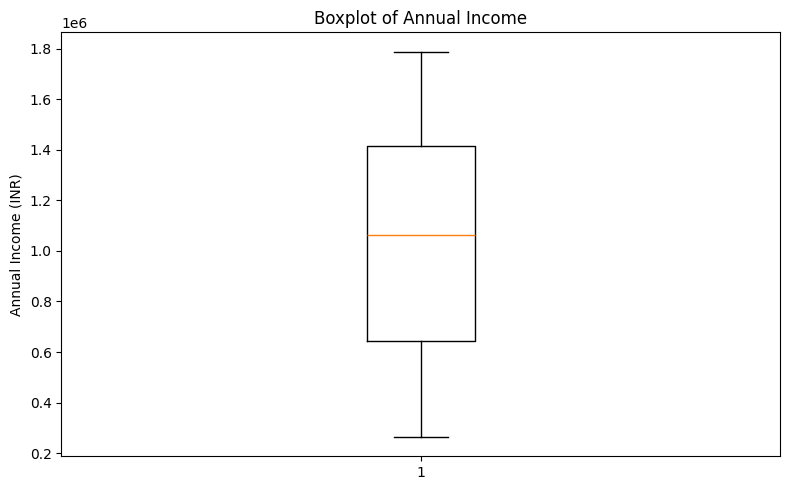

In [34]:
# ============================================================
# EXERCISE 17
# BOXPLOT — ANNUAL INCOME
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.boxplot(
    df["Annual_Income_INR"]
)


plt.ylabel(
    "Annual Income (INR)"
)


plt.title(
    "Boxplot of Annual Income"
)


plt.tight_layout()


plt.show()

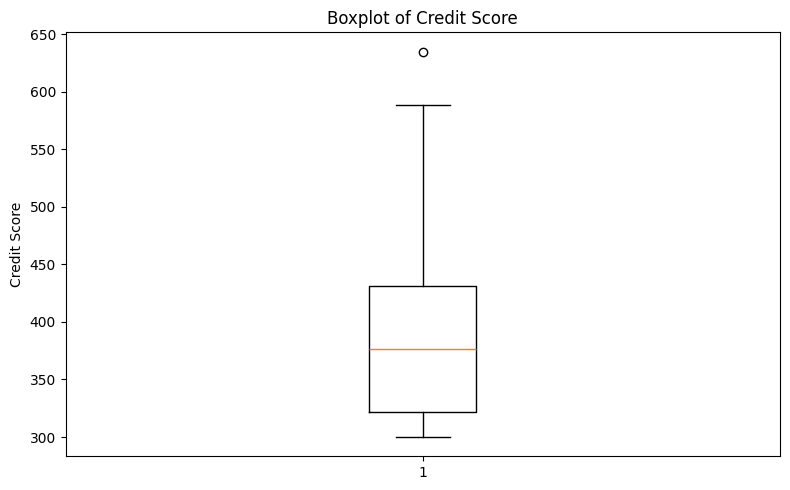

In [38]:
# ============================================================
# BOXPLOT — CREDIT SCORE
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.boxplot(
    df["Credit_Score"]
)


plt.ylabel(
    "Credit Score"
)


plt.title(
    "Boxplot of Credit Score"
)

plt.tight_layout()

plt.show()


In [36]:
# ============================================================
# EXERCISE 18
# LOGISTIC REGRESSION — DEFAULT / NO DEFAULT
# ============================================================

print("""
EXERCISE 18

1. Default/No Default is a binary categorical target,
   whereas Linear Regression is designed for continuous
   numerical targets such as Credit_Score.

2. Logistic Regression models the probability of belonging
   to a binary class, making it suitable for classification
   tasks such as Default/No Default.
""")



EXERCISE 18

1. Default/No Default is a binary categorical target,
   whereas Linear Regression is designed for continuous
   numerical targets such as Credit_Score.

2. Logistic Regression models the probability of belonging
   to a binary class, making it suitable for classification
   tasks such as Default/No Default.



In [37]:
# ============================================================
# FINAL MODEL RESULTS
# ============================================================

print(
    "=========================================="
)

print(
    "FINAL MULTIPLE LINEAR REGRESSION RESULTS"
)

print(
    "=========================================="
)


print(
    f"MAE  : {mae:.4f}"
)

print(
    f"MSE  : {mse:.4f}"
)

print(
    f"RMSE : {rmse:.4f}"
)

print(
    f"R²   : {r2:.4f}"
)


print(
    "\nIntercept (β0):"
)

print(
    model.intercept_
)


print(
    "\nCoefficients:"
)

display(
    coefficients.to_frame(
        "Coefficient"
    )
)

FINAL MULTIPLE LINEAR REGRESSION RESULTS
MAE  : 22.1291
MSE  : 719.4409
RMSE : 26.8224
R²   : 0.8258

Intercept (β0):
410.07497658346506

Coefficients:


,Coefficient
Age,-0.054044
Annual_Income_INR,0.000086
Debt_to_Income_Ratio,-138.191201
Late_Payments_12M,-16.219479
Credit_History_Years,2.805101
Credit_Utilization_Ratio,-65.775940
Existing_Loans,-4.594719
Employment_Years,1.854367
